# Position held: individuals with a dated position, per century

In [1]:
import json
import re
import sys
import tempfile

import duckdb
import matplotlib.pyplot as plt
import polars as pl

sys.path.insert(0, '../notebooks_analysis')
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from style import *

DB_PATH = '../../data/cultura/cultura_enriched_v3.2.duckdb'  # read only: birth years
POSITIONS_PATH = '../../data/raw_data_from_wikidata/wikidata_extraction_scripts_v2/life_locations/position_held_P39_statements.json'  # raw P39 statements
TARGETS_PATH = '../../data/raw_data_from_wikidata/wikidata_extraction_scripts_v2/life_locations/targets.json'  # raw labels of the positions
FIRST_CENTURY, LAST_CENTURY = -500, 1900
CENTURY = 100  # years
PEOPLE = {'Q140412': 'John Donne', 'Q154959': 'Hugo Grotius', 'Q265398': 'Clara Peeters', 'Q296367': 'Hong Taiji'}  # contemporaries, all alive 1592–1631: Europe and China, culture, science and leadership, one woman
WORK_COLOR, POSITION_COLOR = '#D55E00', '#0072B2'  # Okabe-Ito vermillion and blue: distinct hues, colorblind-safe, readable as text
LIFELINE_COLOR = '#b0b6bd'
MILESTONE_COLORS = {'first work': WORK_COLOR, 'last work': WORK_COLOR, 'first position': POSITION_COLOR, 'last position': POSITION_COLOR}
MILESTONE_SIDES = {'first work': 1, 'last work': 1, 'first position': -1, 'last position': -1}  # works above the timeline, positions below; of two labels on a side, the first ends at its event and the second starts at its event

pl.Config.set_tbl_rows(40)
apply_style()

## Data
Raw Wikidata position held (P39) statements, deprecated ones dropped. A position counts only with both a start time (P580) and an end time (P582); a position without them, or with a point in time (P585) only, does not count. Individuals are placed in their century of birth (`individual_enriched`, Wikidata or estimated).

In [2]:
def year(value):
    sign, digits = re.match(r'([+-]?)(\d+)-', value['time']).groups()
    return -int(digits) if sign == '-' else int(digits)


raw = json.load(open(POSITIONS_PATH))
positions = pl.DataFrame(
    [
        {'qid': qid, 'position_qid': statement['target'],
         'start_year': year(statement['start']) if statement['start'] else None, 'start_precision': statement['start']['precision'] if statement['start'] else None,
         'end_year': year(statement['end']) if statement['end'] else None, 'end_precision': statement['end']['precision'] if statement['end'] else None,
         'point_in_time': statement['point_in_time'] is not None}
        for qid, statements in raw.items() for statement in statements if statement['rank'] != 'deprecated'
    ],
    schema={'qid': pl.String, 'position_qid': pl.String, 'start_year': pl.Int64, 'start_precision': pl.Int64, 'end_year': pl.Int64, 'end_precision': pl.Int64, 'point_in_time': pl.Boolean},
)
del raw
dated = positions.filter(pl.col('start_year').is_not_null() & pl.col('end_year').is_not_null())
print(f"{positions['qid'].n_unique():,} individuals with a position held, {dated['qid'].n_unique():,} with at least one position with a start and an end")
dated.sample(5, seed=42)

979,289 individuals with a position held, 454,417 with at least one position with a start and an end


qid,position_qid,start_year,start_precision,end_year,end_precision,point_in_time
str,str,i64,i64,i64,i64,bool
"""Q65593540""","""Q65482993""",2014,11,2020,11,false
"""Q21001584""","""Q18171345""",2009,11,2011,11,false
"""Q98247472""","""Q65477748""",2020,11,2026,11,false
"""Q6214979""","""Q81531912""",1873,9,1875,9,false
"""Q65585278""","""Q65192029""",2014,11,2020,11,false


In [3]:
con = duckdb.connect(DB_PATH, read_only=True)
births = con.sql('''
    SELECT entity.qid AS qid, birth_date.year AS birth_year, death_date.year AS death_year
    FROM   individual_enriched
    WHERE  birth_date.year IS NOT NULL
''').pl()
con.close()
born_per_century = births.group_by((pl.col('birth_year') // CENTURY * CENTURY).alias('century')).agg(pl.len().alias('individuals born'))
print(f'{births.height:,} individuals with a birth year')

7,641,351 individuals with a birth year


## Preprocessing
### Individuals with a dated position, per century of birth

In [4]:
with_dated_position = pl.DataFrame({'qid': dated['qid'].unique()}).join(births, on='qid', how='left')
print(f"{with_dated_position['birth_year'].null_count():,} of {with_dated_position.height:,} individuals with a dated position have no birth year and are left out")

per_century = (
    with_dated_position.drop_nulls('birth_year')
    .group_by((pl.col('birth_year') // CENTURY * CENTURY).alias('century')).agg(pl.len().alias('with a dated position'))
    .join(born_per_century, on='century', how='right')
    .filter(pl.col('century').is_between(FIRST_CENTURY, LAST_CENTURY))
    .with_columns(pl.col('with a dated position').fill_null(0))
    .with_columns((100 * pl.col('with a dated position') / pl.col('individuals born')).round(2).alias('% of individuals born'))
    .select('century', 'individuals born', 'with a dated position', '% of individuals born')
    .sort('century')
)
assert per_century['century'].is_unique().all()
per_century

53,878 of 454,417 individuals with a dated position have no birth year and are left out


century,individuals born,with a dated position,% of individuals born
i64,u32,u32,f64
-500,443,72,16.25
-400,596,104,17.45
-300,702,236,33.62
-200,701,234,33.38
-100,949,166,17.49
0,928,142,15.3
100,1316,96,7.29
200,1718,138,8.03
300,1810,226,12.49


### Dates of the position-held statements
Each statement by the dates it carries: start and end, start only, end only, a point in time only, no date.

In [5]:
dates_carried = positions.with_columns(
    pl.when(pl.col('start_year').is_not_null() & pl.col('end_year').is_not_null()).then(pl.lit('start and end'))
    .when(pl.col('start_year').is_not_null()).then(pl.lit('start only'))
    .when(pl.col('end_year').is_not_null()).then(pl.lit('end only'))
    .when(pl.col('point_in_time')).then(pl.lit('point in time only'))
    .otherwise(pl.lit('no date')).alias('dates')
)
statement_dates = (
    dates_carried.group_by('dates').agg(pl.len().alias('statements'), pl.col('qid').n_unique().alias('individuals'))
    .with_columns((100 * pl.col('statements') / pl.col('statements').sum()).round(1).alias('% of statements'))
    .sort('statements', descending=True)
)
start_only_people = dates_carried.group_by('qid').agg((pl.col('dates') == 'start only').any().alias('start only'), (pl.col('dates') == 'start and end').any().alias('start and end'))
print(f"{start_only_people.filter('start only').height:,} individuals have a position with a start and no end; "
      f"{start_only_people.filter(pl.col('start only') & ~pl.col('start and end')).height:,} of them have no position with both dates")
statement_dates

208,762 individuals have a position with a start and no end; 115,937 of them have no position with both dates


dates,statements,individuals,% of statements
str,u32,u32,f64
"""start and end""",983518,454417,50.5
"""no date""",662594,485169,34.0
"""start only""",284335,208762,14.6
"""end only""",9308,8763,0.5
"""point in time only""",7376,6701,0.4


### Individuals with at least two dated works or positions, per century of birth
A dated event is a dated work (inception, else publication, precise to the year or the decade, a decade counting as its middle year) or a position with a start and an end (at its start year), inside the lifetime (birth to death, or 100 years after the birth). An individual counts with at least two events in different years: two works, two positions, or a work and a position.

In [6]:
con = duckdb.connect(DB_PATH, read_only=True)
con.sql(f"SET memory_limit='6GB'; SET temp_directory='{tempfile.mkdtemp()}'")
con.register('position_starts', dated.select('qid', pl.col('start_year').alias('year')).unique().to_arrow())
con.register('births', births.to_arrow())
dated_events = con.sql('''
    WITH work_years AS (
        SELECT DISTINCT individual_work.qid,
               CASE WHEN list_contains(['day', 'month', 'year', 'decade'], work.inception.precision)
                    THEN work.inception.year + CASE WHEN work.inception.precision = 'decade' THEN 5 ELSE 0 END
                    ELSE work.publication_date.year + CASE WHEN work.publication_date.precision = 'decade' THEN 5 ELSE 0 END END AS year
        FROM   individual_work
        JOIN   work ON work.entity.qid = individual_work.work_qid
        WHERE  list_contains(['day', 'month', 'year', 'decade'], work.inception.precision) OR list_contains(['day', 'month', 'year', 'decade'], work.publication_date.precision)
    ),
    events AS (
        SELECT qid, year, 'work' AS kind FROM work_years
        UNION ALL
        SELECT qid, year, 'position' AS kind FROM position_starts
    )
    SELECT births.qid, births.birth_year // $century * $century AS century,
           count(DISTINCT events.year) AS years,
           count(*) FILTER (WHERE events.kind = 'work') AS works,
           count(*) FILTER (WHERE events.kind = 'position') AS positions
    FROM   events
    JOIN   births ON births.qid = events.qid
    WHERE  events.year BETWEEN births.birth_year AND coalesce(births.death_year, births.birth_year + 100)
    GROUP BY ALL
    HAVING count(DISTINCT events.year) >= 2
''', params={'century': CENTURY}).pl()
con.close()

EVENT_KINDS = {'works only': (pl.col('positions') == 0), 'positions only': (pl.col('works') == 0), 'works and positions': (pl.col('works') > 0) & (pl.col('positions') > 0)}
two_events = (
    dated_events.filter(pl.col('century').is_between(FIRST_CENTURY, LAST_CENTURY))
    .group_by('century').agg(pl.len().alias('at least two dated events'), *[condition.sum().alias(kind) for kind, condition in EVENT_KINDS.items()])
    .sort('century')
)
assert (two_events['at least two dated events'] == two_events.select(list(EVENT_KINDS)).sum_horizontal()).all()
print(f"{dated_events.height:,} individuals with at least two dated events in different years")
two_events

497,636 individuals with at least two dated events in different years


century,at least two dated events,works only,positions only,works and positions
i64,u32,u32,u32,u32
-500,23,4,18,1
-400,25,10,14,1
-300,24,4,17,3
-200,79,1,74,4
-100,75,0,73,2
0,100,7,85,8
100,20,3,15,2
200,14,1,7,6
300,23,5,12,6


### Example individuals
Four contemporaries, all alive from 1592 to 1631 (Europe and China; culture, science and leadership; one woman): birth, first and last dated work (notebook 02, titled works only), start of their first position and end of their last position (start and end both dated), death.

In [7]:
position_spans = dated.group_by('qid').agg(
    pl.col('start_year').min().alias('first_position'),
    pl.col('position_qid').sort_by('start_year').first().alias('first_position_qid'),
    pl.col('end_year').max().alias('last_position'),
    pl.col('position_qid').sort_by('end_year').last().alias('last_position_qid'),
)
con = duckdb.connect(DB_PATH, read_only=True)
con.register('position_spans', position_spans.to_arrow())
people = con.sql('''
    SELECT individual_enriched.entity.qid AS qid,
           individual_enriched.entity.label_en AS name,
           individual_enriched.birth_date.year AS birth_year,
           individual_enriched.death_date.year AS death_year,
           position_spans.first_position,
           position_spans.first_position_qid,
           position_spans.last_position,
           position_spans.last_position_qid
    FROM   individual_enriched
    LEFT JOIN position_spans ON position_spans.qid = individual_enriched.entity.qid
    WHERE  list_contains($qids, individual_enriched.entity.qid)
''', params={'qids': list(PEOPLE)}).pl()

works = con.sql('''
    WITH dated AS (
        SELECT individual_work.qid,
               coalesce(work.entity.label_en, work.entity.label_non_en) AS work_name,
               CASE WHEN list_contains(['day', 'month', 'year', 'decade'], work.inception.precision) THEN work.inception ELSE work.publication_date END AS date
        FROM   individual_work
        JOIN   work ON work.entity.qid = individual_work.work_qid
        WHERE  list_contains($qids, individual_work.qid)
    )
    SELECT qid, work_name, date.year + CASE WHEN date.precision = 'decade' THEN 5 ELSE 0 END AS year
    FROM   dated
    WHERE  list_contains(['day', 'month', 'year', 'decade'], date.precision) AND work_name IS NOT NULL
''', params={'qids': list(PEOPLE)}).pl()
con.close()

work_spans = (
    works.join(people.select('qid', 'birth_year', 'death_year'), on='qid')
    .filter(pl.col('year').is_between('birth_year', 'death_year'))  # a work date must fall inside the lifetime (cleaning rule 2 of 03_b_active_life)
    .group_by('qid').agg(pl.col('year').min().alias('first_work'), pl.col('year').max().alias('last_work'))
)
people = people.join(work_spans, on='qid', how='left')

first_names = works.join(people.select('qid', 'first_work'), on='qid').filter(pl.col('year') == pl.col('first_work')).group_by('qid').agg(pl.col('work_name').min().alias('first_work_name'))
last_names = works.join(people.select('qid', 'last_work'), on='qid').filter(pl.col('year') == pl.col('last_work')).group_by('qid').agg(pl.col('work_name').min().alias('last_work_name'))

targets = json.load(open(TARGETS_PATH))
position_label = {qid: (targets.get(qid) or {}).get('label_en') or qid for qid in [*people['first_position_qid'].drop_nulls(), *people['last_position_qid'].drop_nulls()]}
del targets
people = (
    people.join(first_names, on='qid', how='left').join(last_names, on='qid', how='left')
    .with_columns(
        pl.col('first_position_qid').replace_strict(position_label, default=None).alias('first_position_name'),
        pl.col('last_position_qid').replace_strict(position_label, default=None).alias('last_position_name'),
    )
    .sort('birth_year')
)
assert people.height == len(PEOPLE)
people.select('name', 'birth_year', 'first_work', 'first_work_name', 'last_work', 'last_work_name', 'first_position', 'first_position_name', 'last_position', 'last_position_name', 'death_year')

name,birth_year,first_work,first_work_name,last_work,last_work_name,first_position,first_position_name,last_position,last_position_name,death_year
str,i64,i64,str,i64,str,i64,str,i64,str,i64
"""John Donne""",1572,1609,"""Death Be Not Proud""",1624,"""Devotions upon Emergent Occasi…",1621,"""Dean of St Paul's""",1631,"""Dean of St Paul's""",1631
"""Hugo Grotius""",1583,1608,"""Christus patiens""",1625,"""De jure belli ac pacis""",1613,"""Pensionary""",1618,"""Pensionary""",1645
"""Clara Peeters""",1587,1600,"""Flowers in a glass beaker, wit…",1640,"""Basket of red and green grapes…",null,null,null,null,1657
"""Hong Taiji""",1592,null,null,null,null,1626,"""khan""",1643,"""Emperor of China""",1643


## Figures
### Figure 1: Individuals with a dated position held, per century of birth

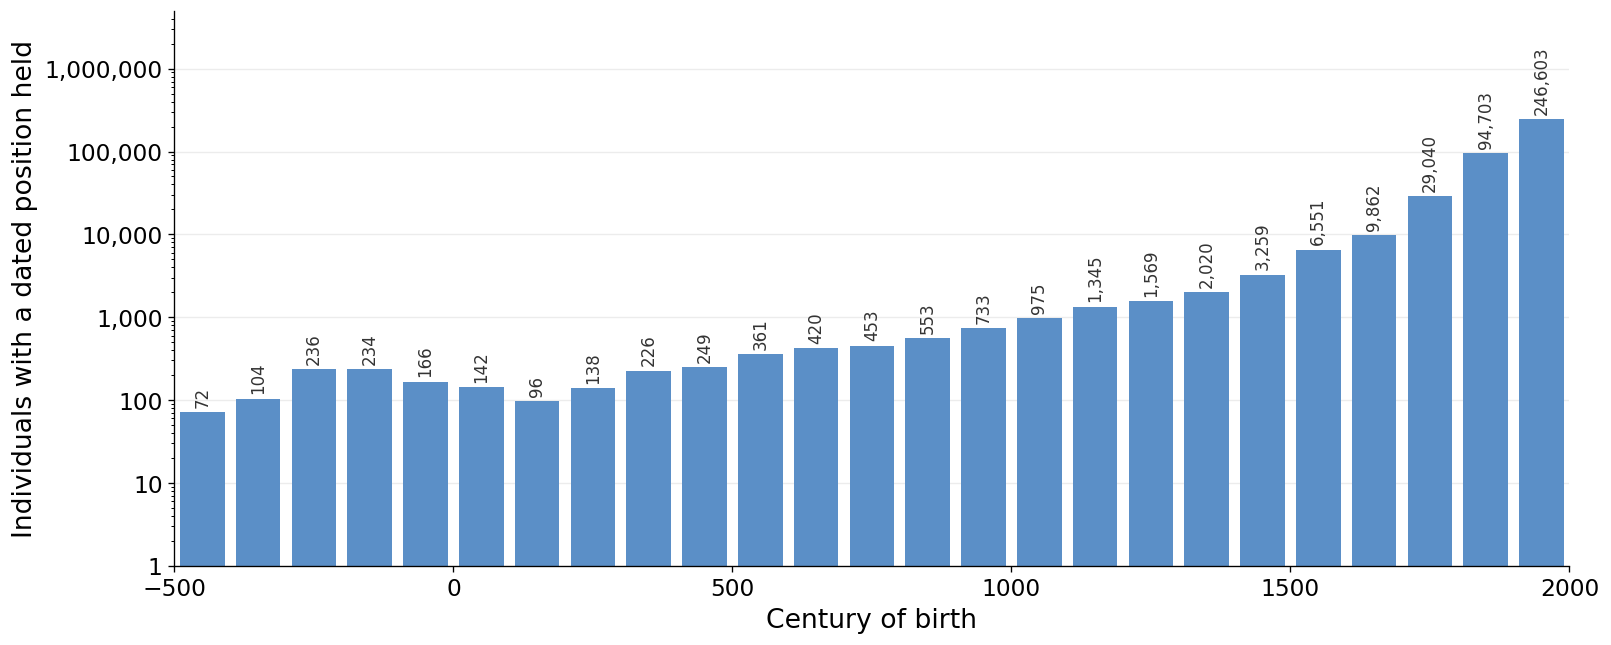

In [8]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
ax.bar(per_century['century'] + CENTURY / 2, per_century['with a dated position'], width=CENTURY * 0.8, color=MAIN_COLOR)
for century, n in per_century.select('century', 'with a dated position').iter_rows():
    ax.text(century + CENTURY / 2, n * 1.15, f'{n:,}', ha='center', va='bottom', fontsize=VALUE_LABEL_FONTSIZE - 2, rotation=90, color=TEXT)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_ylim(1, per_century['with a dated position'].max() * 20)
ax.set_xlim(FIRST_CENTURY, LAST_CENTURY + CENTURY)
ax.set_xlabel('Century of birth')
ax.set_ylabel('Individuals with a dated position held')
ax.grid(axis='y')
plt.show()

### Figure 2: Share of the individuals born in each century with a dated position held

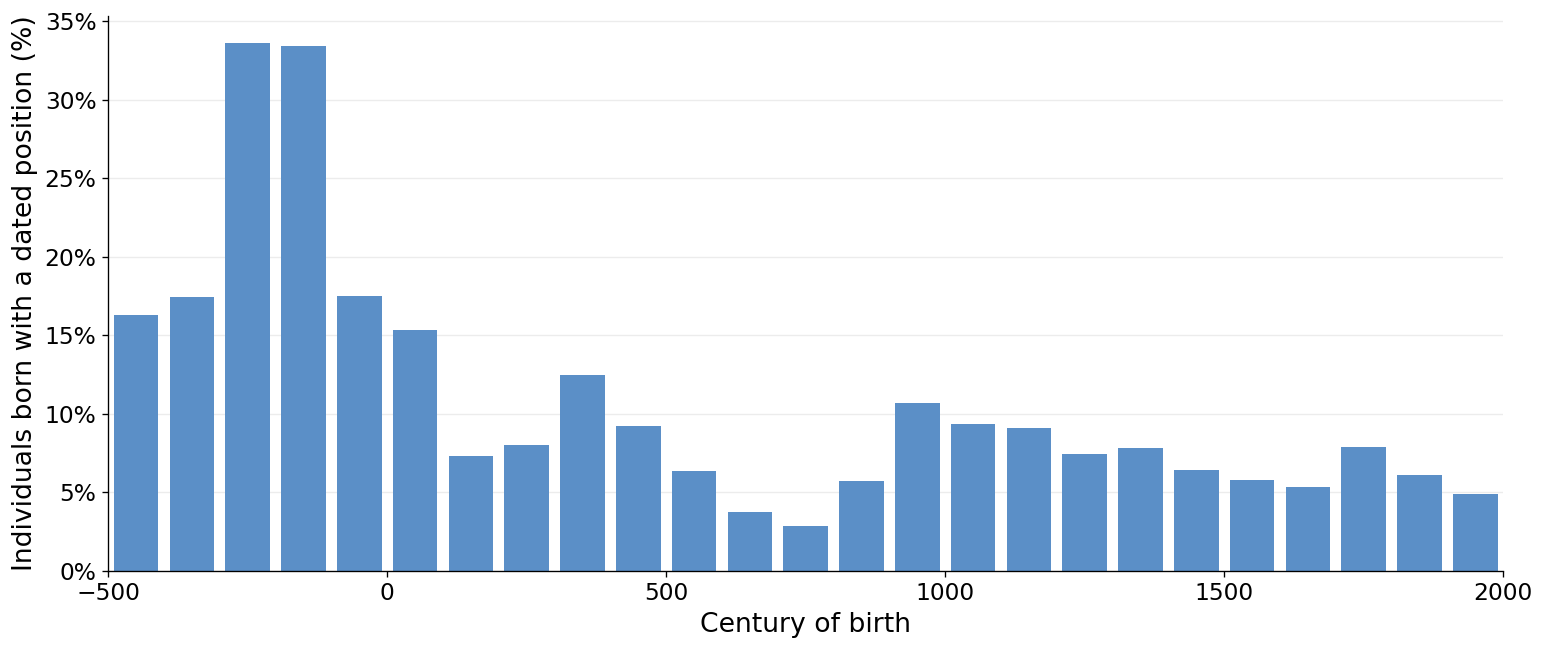

In [9]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
ax.bar(per_century['century'] + CENTURY / 2, per_century['% of individuals born'], width=CENTURY * 0.8, color=MAIN_COLOR)
ax.set_xlim(FIRST_CENTURY, LAST_CENTURY + CENTURY)
ax.yaxis.set_major_formatter(PERCENT)
ax.set_xlabel('Century of birth')
ax.set_ylabel('Individuals born with a dated position (%)')
ax.grid(axis='y')
plt.show()

### Figure 3: Works and positions of five individuals born 1500–1599 in Europe and China

/var/folders/lx/9b13r6ln63jb54_3xlf9b_380000gn/T/ipykernel_88853/3856337526.py:47: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


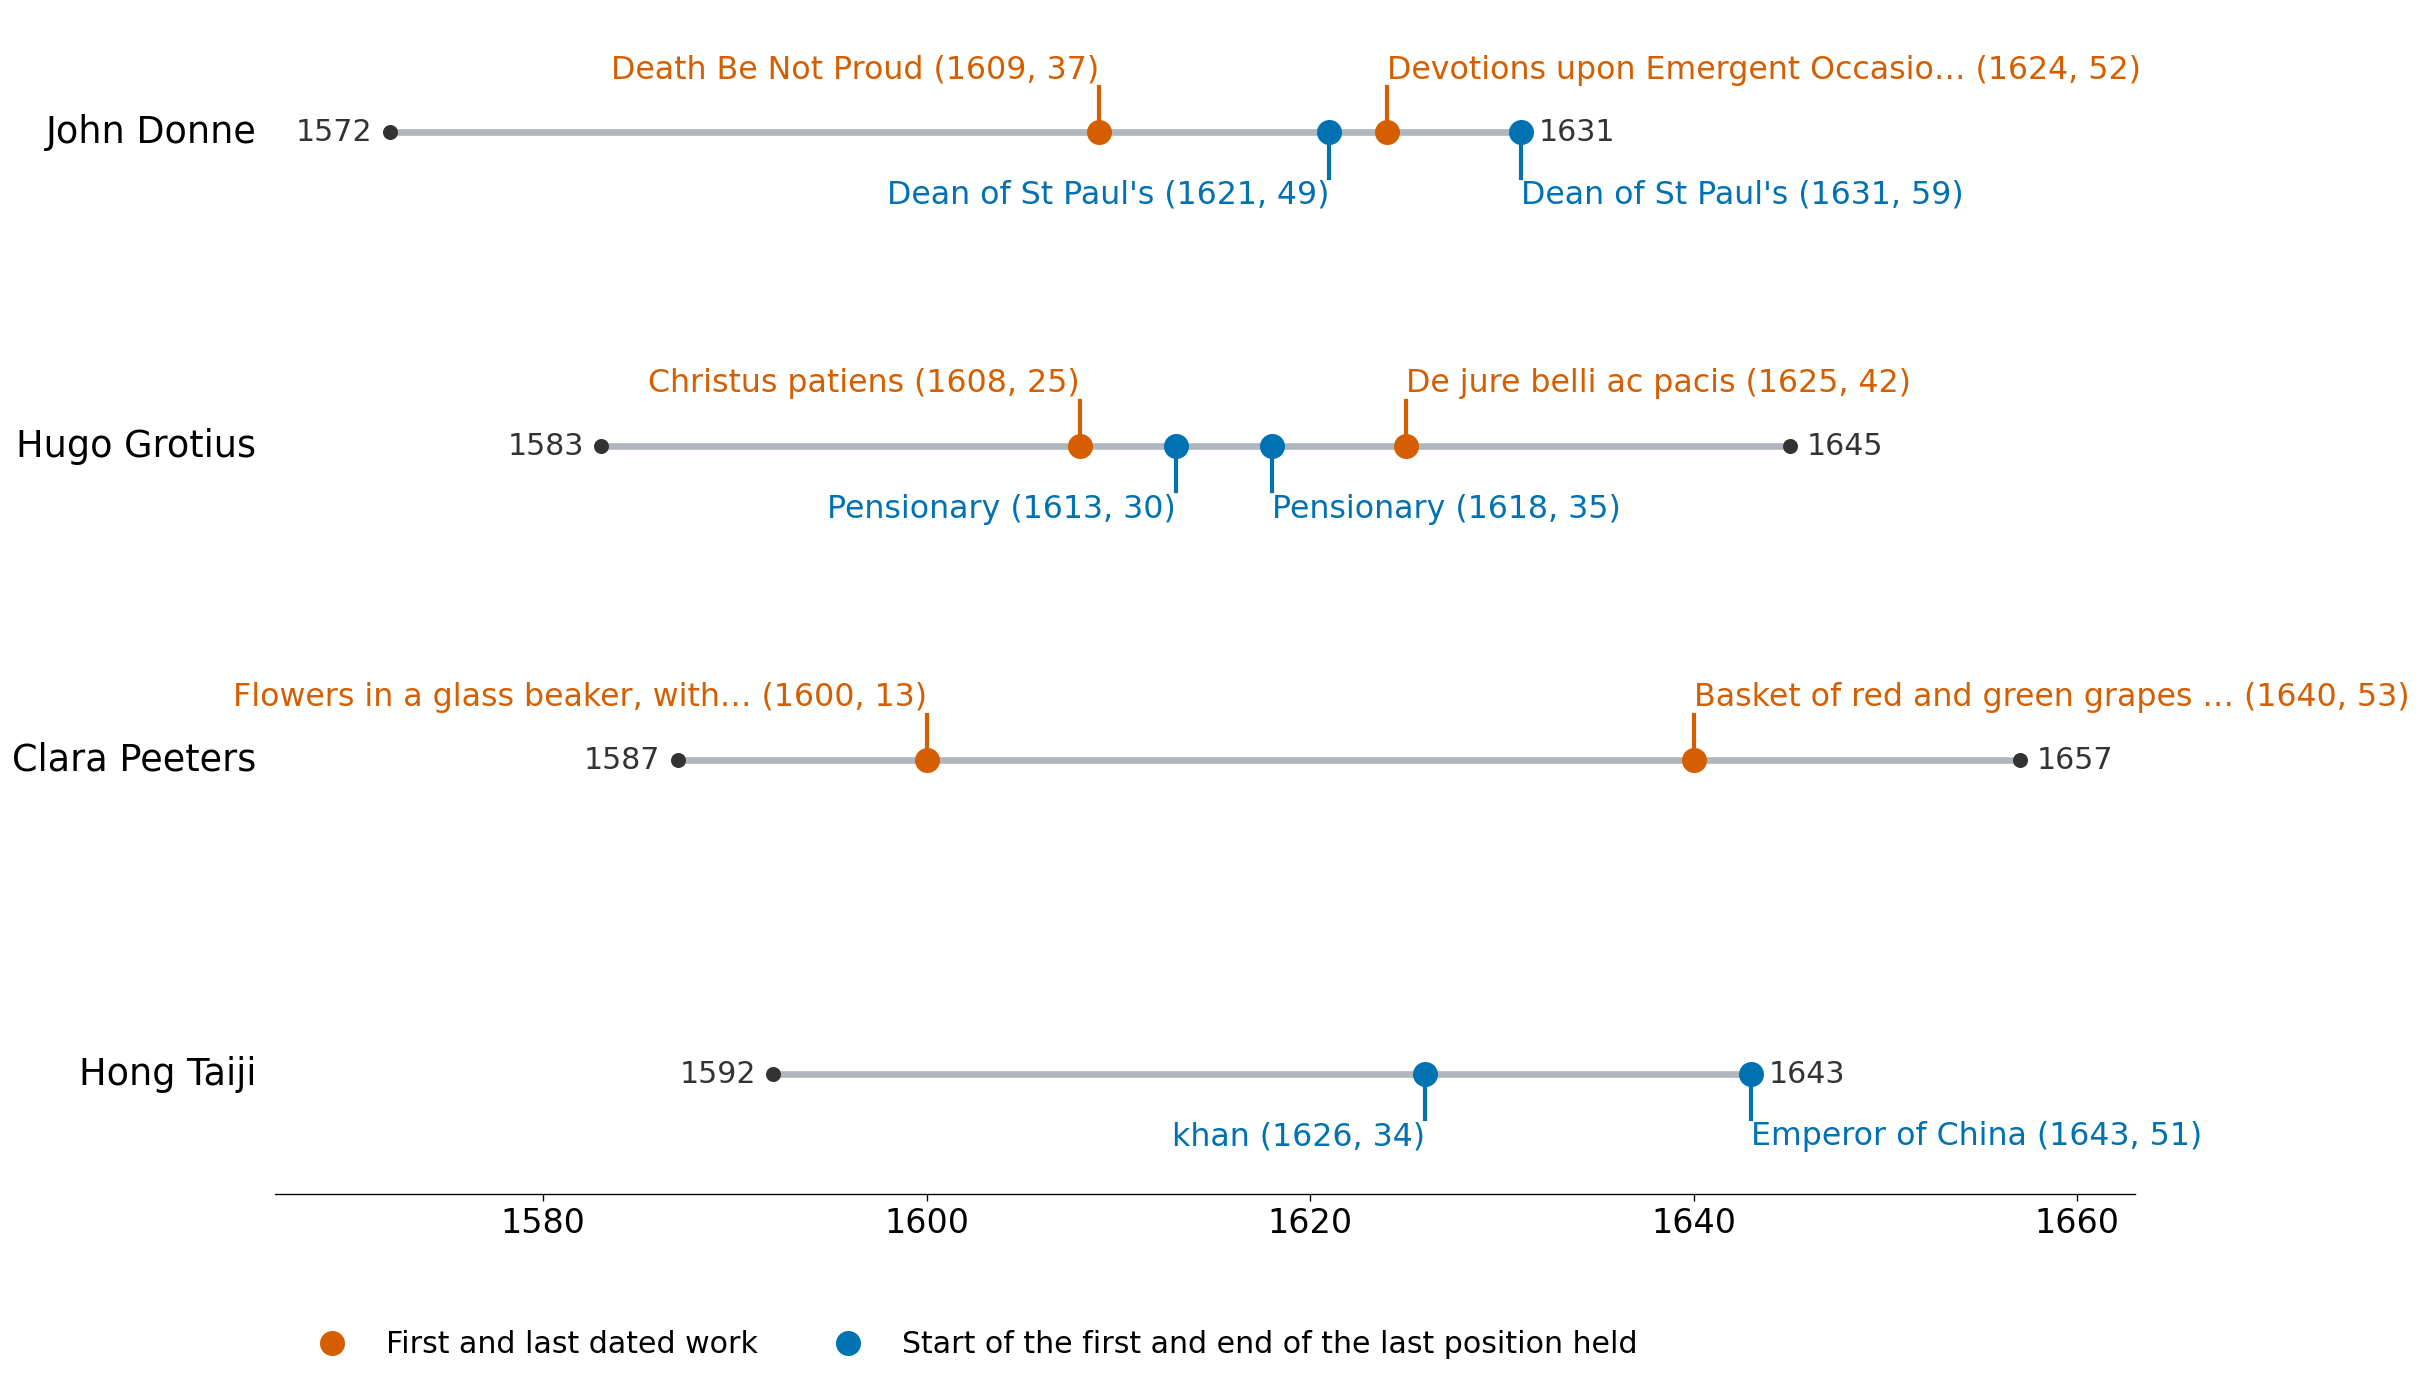

In [10]:
def shorten(text, size=32):
    return text if len(text) <= size else text[:size - 1] + '…'


def milestones(person):
    found = []
    for event, year, name in [('first work', person['first_work'], person['first_work_name']), ('last work', person['last_work'], person['last_work_name']),
                              ('first position', person['first_position'], person['first_position_name']), ('last position', person['last_position'], person['last_position_name'])]:
        if year is not None and name is not None:
            found.append((event, year, name))
    return found


def plot_milestones(frame):
    fig, axes = plt.subplots(frame.height, 1, figsize=(20, 3.2 * frame.height), sharex=True, gridspec_kw={'hspace': 0.3})
    for ax, person in zip(axes, frame.iter_rows(named=True)):
        birth, death = person['birth_year'], person['death_year']
        ax.plot([birth, death], [0, 0], color=LIFELINE_COLOR, linewidth=4, zorder=1)
        for year, ha, shift in [(birth, 'right', -1.5), (death, 'left', 1.5)]:
            ax.plot(year, 0, 'o', color=TEXT, markersize=8, zorder=2)
            ax.text(year + shift * 0.6, 0, year, ha=ha, va='center', fontsize=18, color=TEXT)
        previous = {}
        for event, year, name in sorted(milestones(person), key=lambda milestone: milestone[1]):
            side = MILESTONE_SIDES[event]
            close = side in previous
            color = MILESTONE_COLORS[event]
            ax.plot([year, year], [0, side * 1.2], color=color, linewidth=2.5, zorder=1)
            ax.plot(year, 0, 'o', color=color, markersize=14, zorder=3)
            label = ax.text(year, side * 1.25, f'{shorten(name)} ({year}, {year - birth})', ha='left' if close else 'center',
                            va='top' if side < 0 else 'bottom', fontsize=19, color=color)
            if close:
                previous[side].set_horizontalalignment('right')
            previous[side] = label
        ax.text(-0.01, 0, person['name'], transform=ax.get_yaxis_transform(), ha='right', va='center', fontsize=22, color='black')
        ax.set_ylim(-3.2, 3.2)
        ax.set_yticks([])
        for spine in ('left', 'top', 'right', 'bottom'):
            ax.spines[spine].set_visible(False)
        ax.tick_params(axis='x', length=0)
    axes[-1].spines['bottom'].set_visible(True)
    axes[-1].tick_params(axis='x', length=4, labelsize=20)
    axes[-1].set_xlim(frame['birth_year'].min() - 6, frame['death_year'].max() + 6)
    axes[-1].legend(handles=[
        Line2D([], [], marker='o', linestyle='', markersize=14, color=WORK_COLOR, label='First and last dated work'),
        Line2D([], [], marker='o', linestyle='', markersize=14, color=POSITION_COLOR, label='Start of the first and end of the last position held'),
    ], loc='upper left', bbox_to_anchor=(0, -0.45), ncol=2, fontsize=18)
    plt.tight_layout()
    plt.show()


plot_milestones(people)

### Figure 4: Individuals with at least two dated works or positions, per century of birth

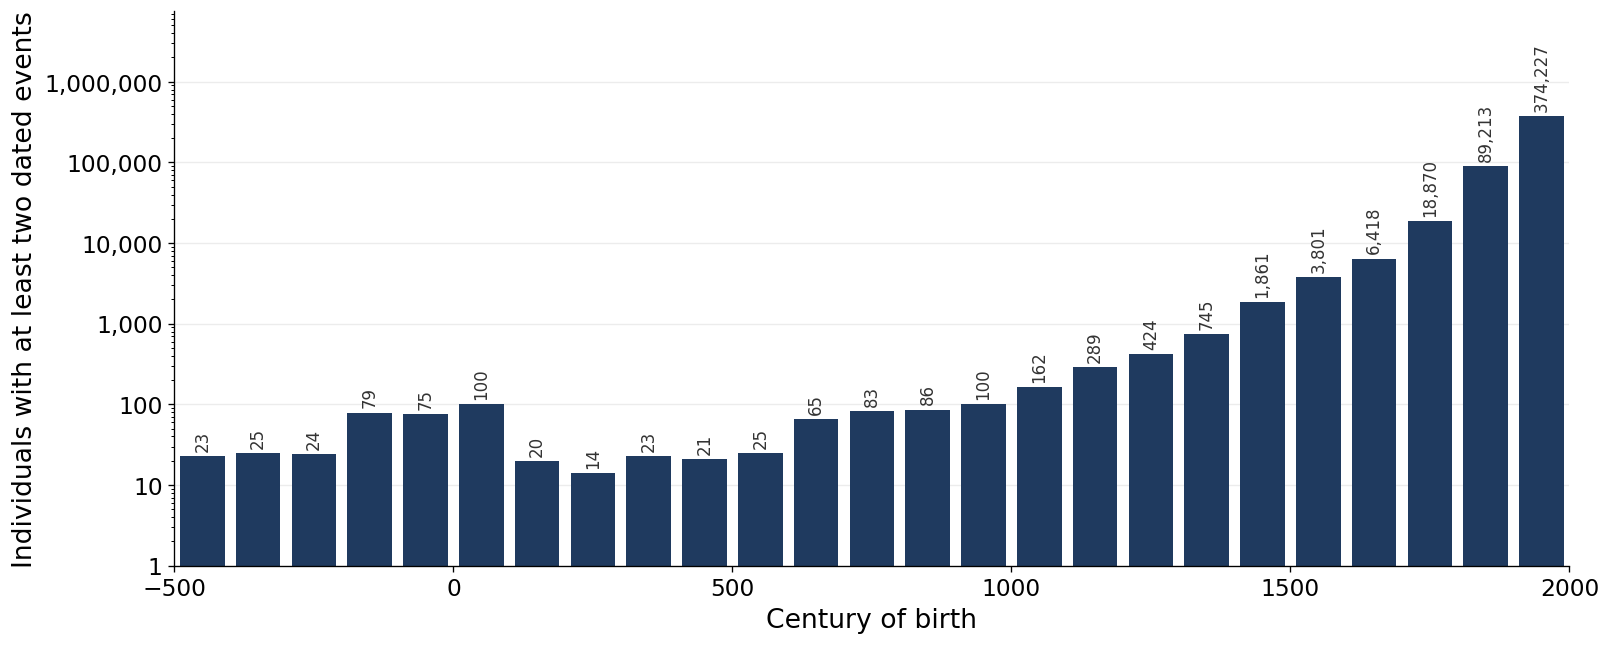

In [11]:
fig, ax = plt.subplots(figsize=FIGSIZE_WIDE)
ax.bar(two_events['century'] + CENTURY / 2, two_events['at least two dated events'], width=CENTURY * 0.8, color=NAVY)
for century, n in two_events.select('century', 'at least two dated events').iter_rows():
    ax.text(century + CENTURY / 2, n * 1.15, f'{n:,}', ha='center', va='bottom', fontsize=VALUE_LABEL_FONTSIZE - 2, rotation=90, color=TEXT)
ax.set_yscale('log')
ax.yaxis.set_major_formatter(THOUSANDS)
ax.set_ylim(1, two_events['at least two dated events'].max() * 20)
ax.set_xlim(FIRST_CENTURY, LAST_CENTURY + CENTURY)
ax.set_xlabel('Century of birth')
ax.set_ylabel('Individuals with at least two dated events')
ax.grid(axis='y')
plt.show()